In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi



In [3]:
# prefix = '/scratch/'
prefix = '/mnt/staging/'
mouse = 'cm193'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
face_h5_root = step_3_root+mouse+'/dlc_face_h5s/'


fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(PREPARES / "index-M1") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"


save_path = str(PREPARES / "heterogeneity") + "/"


# 1. spontaneous running

```
% day2 runCDE 5min
% day3 runBCD 5min
% -------- rig turned 90 ---------
% day4 runBCD 10min
% day5 runCD 10min
% day6 runBCDEFG 10min
% day8 runCMN 10min
```

In [4]:
mouse = 'cm193'
f1 = [f for f in glob.glob(step_1_root + mouse+"/[2]/run[CDE]*.mat", recursive=True)] 
f2 = [f for f in glob.glob(step_1_root + mouse+"/[3-4]/run[BCD]*1.mat", recursive=True)]
f3 = [f for f in glob.glob(step_1_root + mouse+"/[5]/run[C-D]*.mat", recursive=True)]
f4 = [f for f in glob.glob(step_1_root + mouse+"/[6]/run[B-G]*.mat", recursive=True)]

file_spont = f1+f2+f3+f4
file_spont

['/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/2/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/2/runE_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/2/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/3/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/3/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/3/runB_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/4/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/4/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/4/runB_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/5/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm193/5/runC_stim_1.mat',
 '/mnt/staging/users/wx2203/data

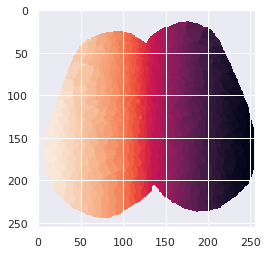

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
plt.imshow(IDX_sorted)

In [6]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

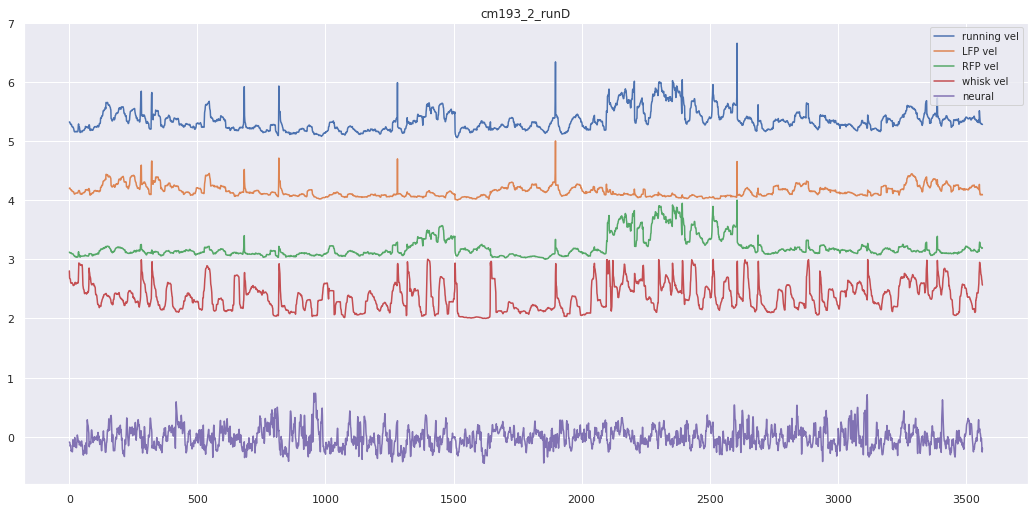

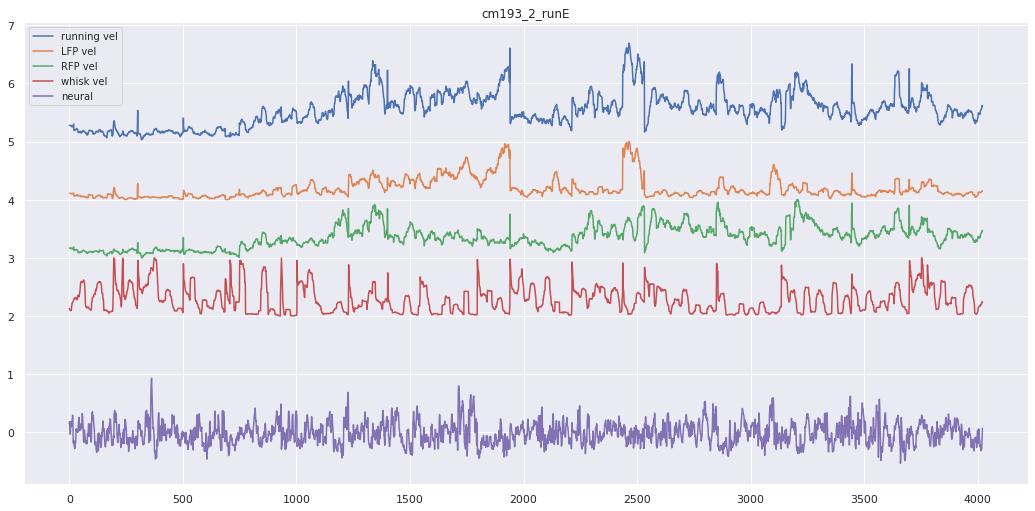

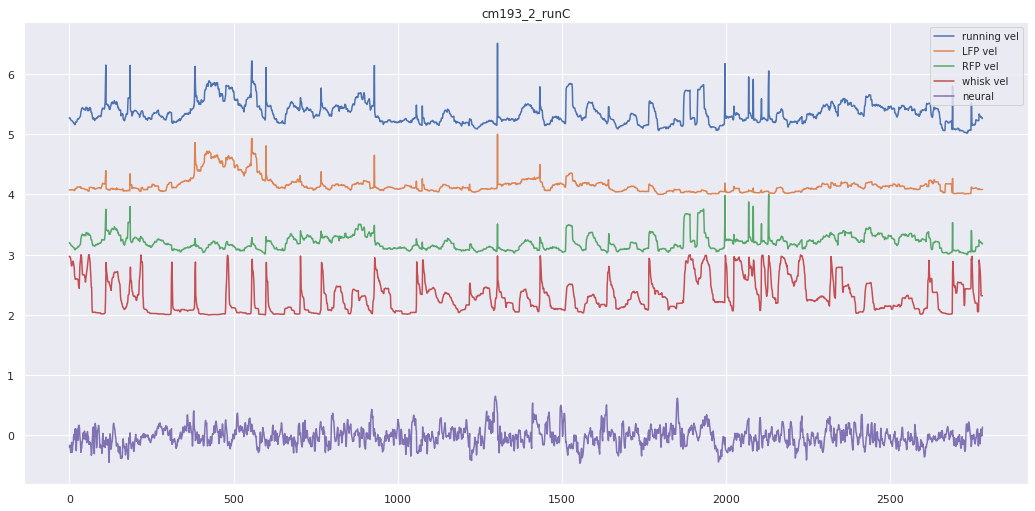

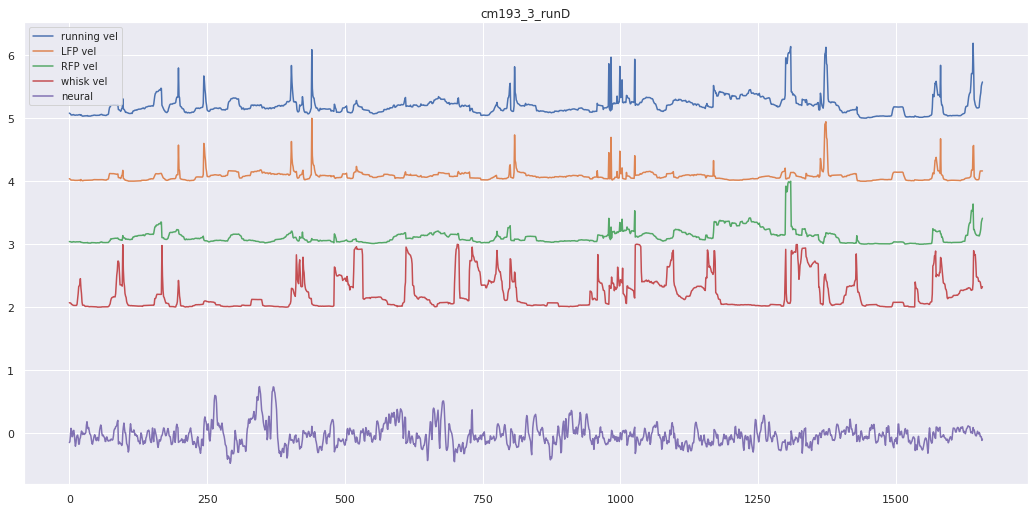

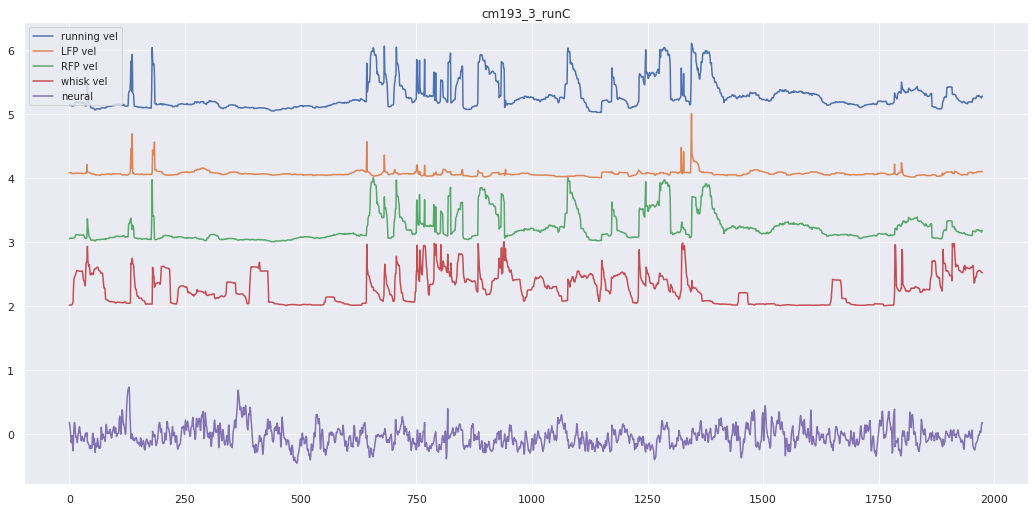

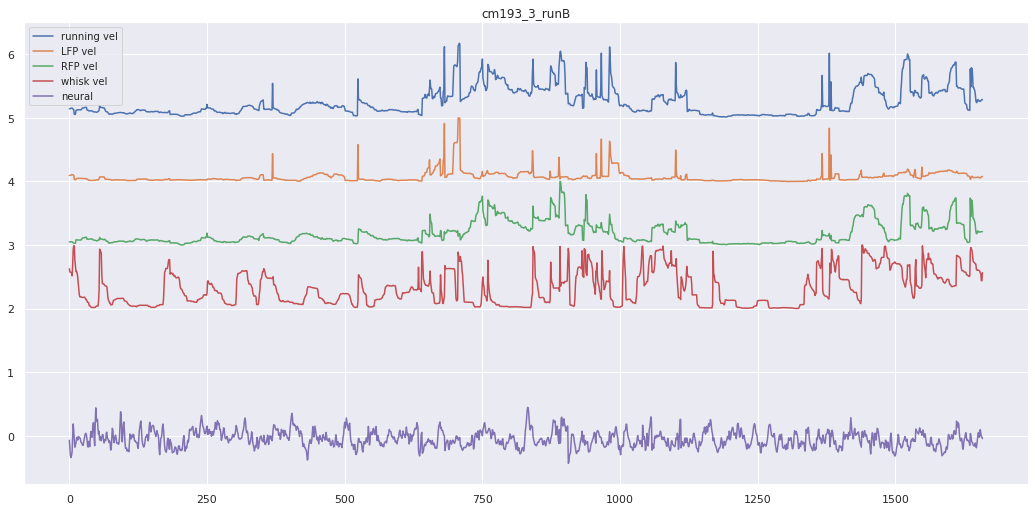

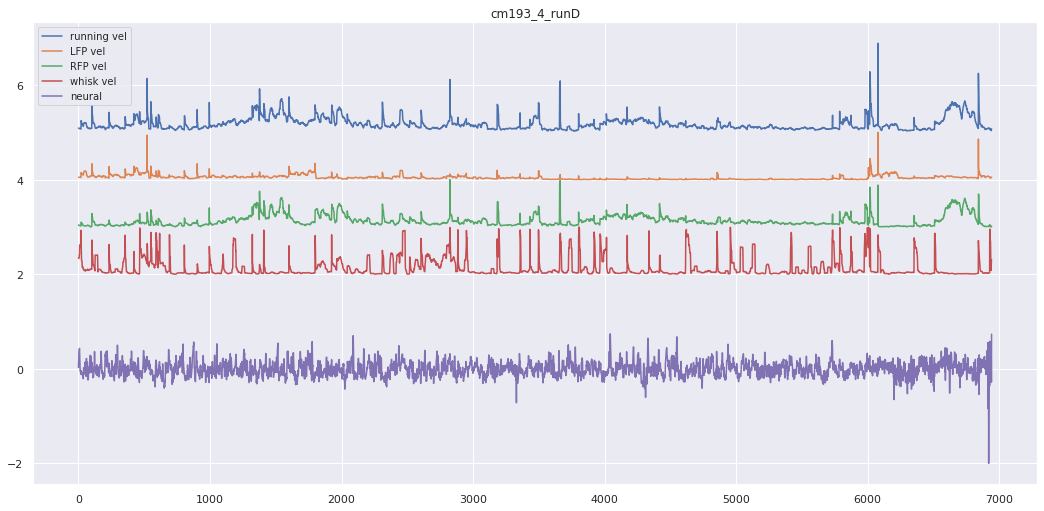

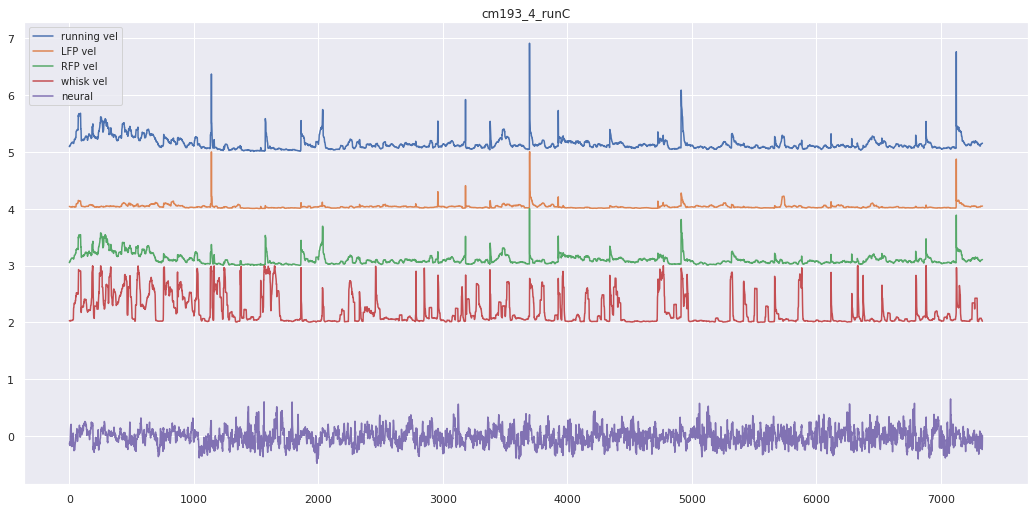

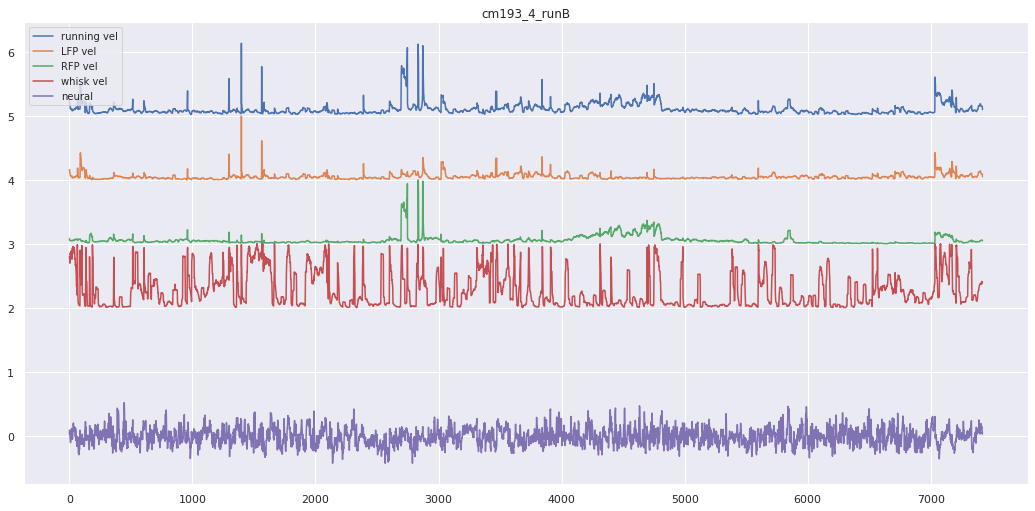

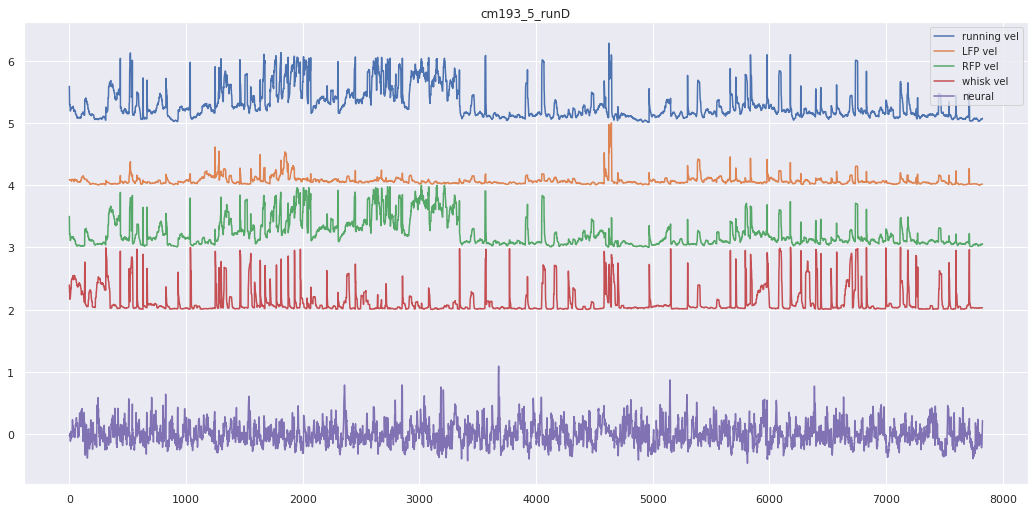

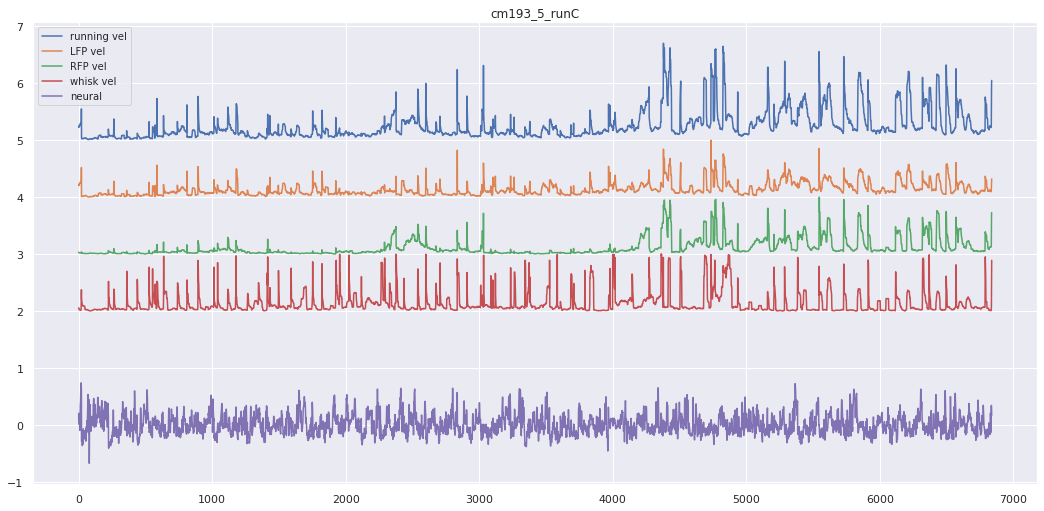

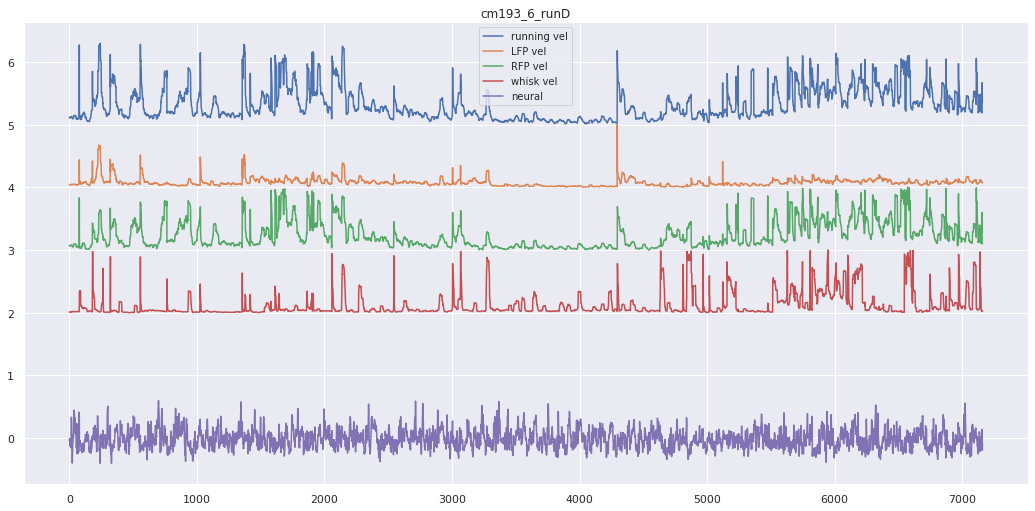

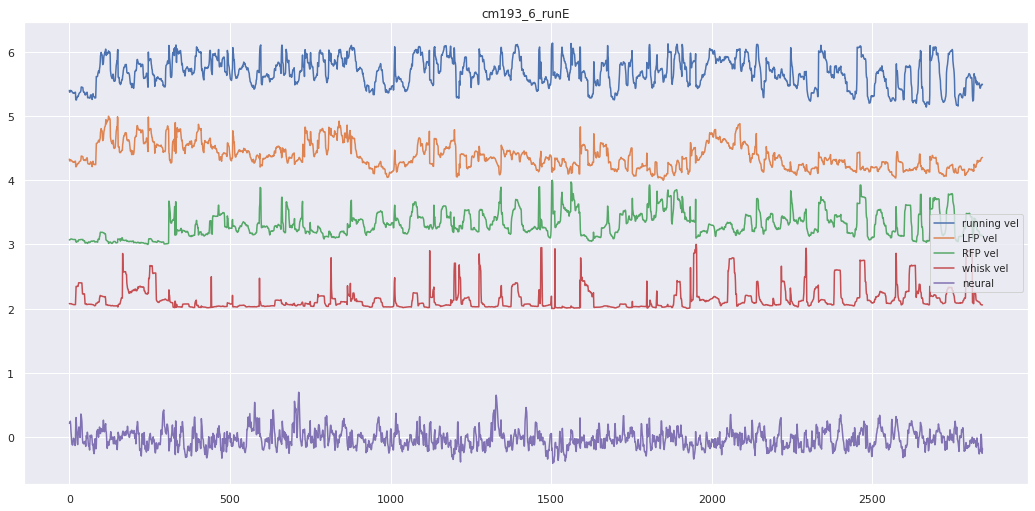

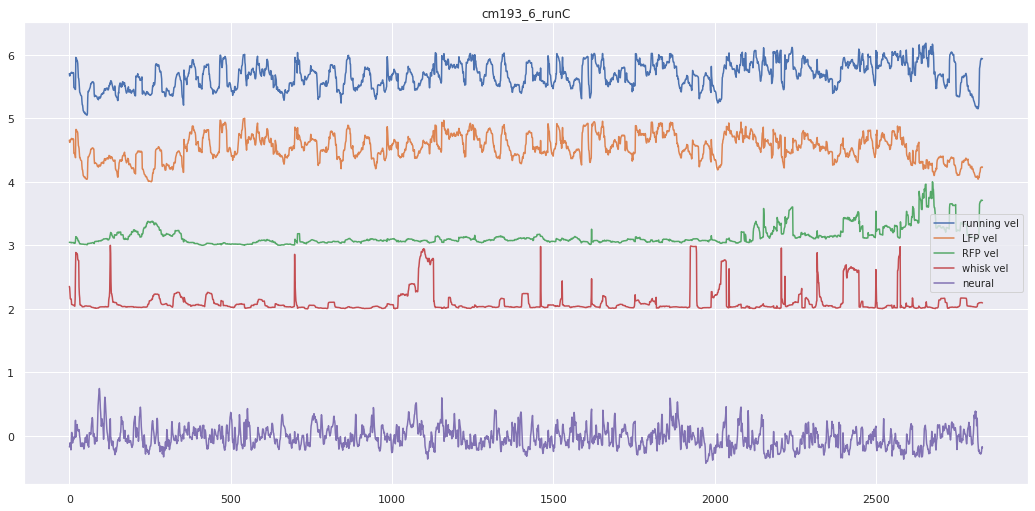

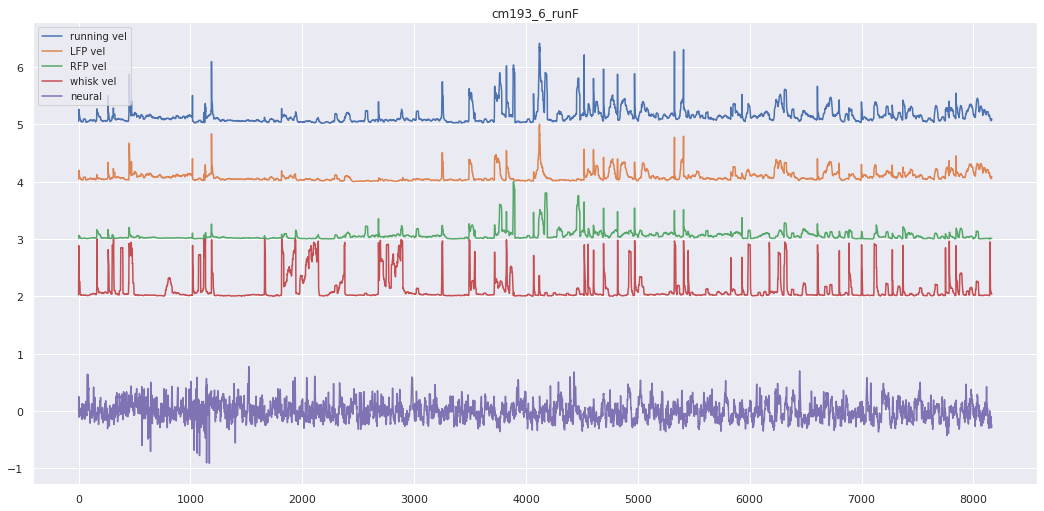

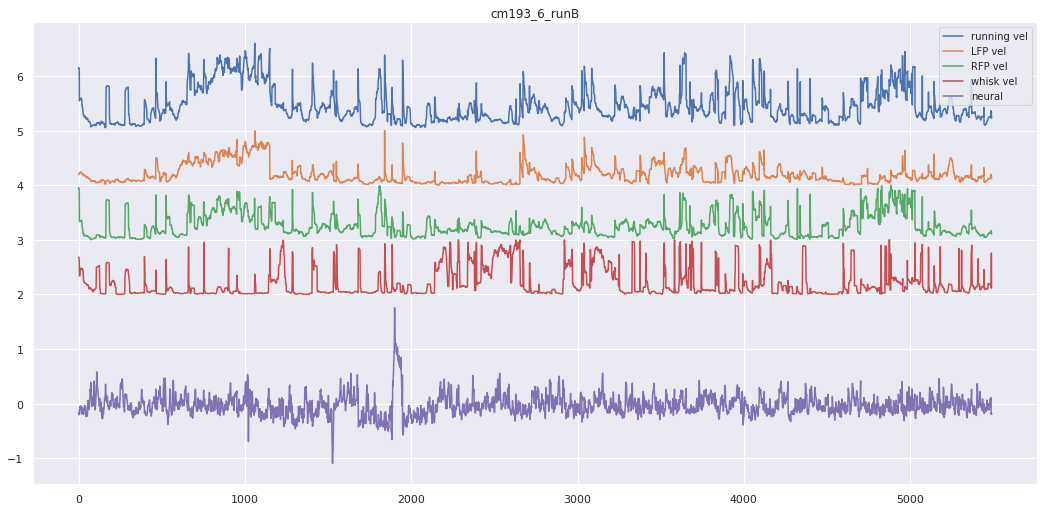

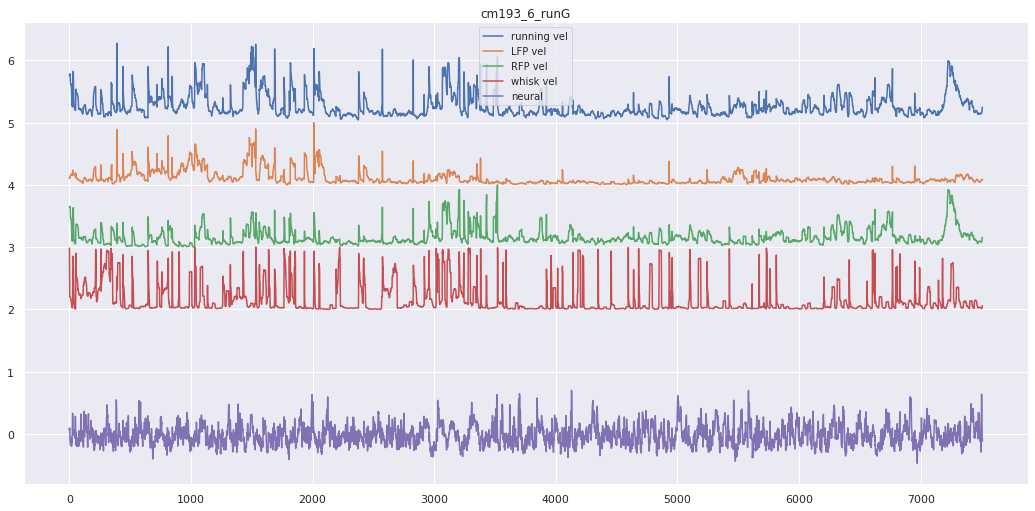

In [12]:
sns.set()
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

M_jrgeco = np.empty((256,256,0))
M_whisk_vel_norm = np.empty((0))
M_LFP_vel_norm = np.empty((0))
M_RFP_vel_norm = np.empty((0))

data_joint=pd.DataFrame()

for i_file,fname in enumerate(file_spont): 
    f = h5py.File(fname,'r')
    ################################### identity 
    run_name = fname.split('_stim_1')[0][-4:]
    day = fname.split(mouse)[1][1:2]
    mouse_day = mouse+'_'+day
    run=run_name
    
#     try:
    f_jrgeco = h5py.File(fname,'r')
    C = np.array(f_jrgeco['C']['jrgeco'])
    S = np.array(f_jrgeco['S']['jrgeco'])
    m = f_jrgeco['m']
    nanidx = np.squeeze(m['nanidx'])
    CS = np.dot(S,C).transpose()
    jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
    jrgeco[:] = np.nan
    jrgeco[nanidx==1,:] = CS
    jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))
    jrgeco = jrgeco[:,:,500:-505]

    #remove tail flip
    H = getH(jrgeco,IDX_sorted)
    ind_tail_flip_to_remove = np.abs(np.mean(H,axis=0))>0.08
    jrgeco = jrgeco[:,:,~ind_tail_flip_to_remove]
    H = H[:,~ind_tail_flip_to_remove]
    total_tpt = jrgeco.shape[-1]
     
#     except:
#         print('missing',mouse,day,'H_'+run+'_stim_1.mat')
#         continue
        
    
    ################################### whisking velocity (11980,)
    try:
        f_name_dlc = glob.glob(face_h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] 
        new_df = Dataframe[scorer] # de-level
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        prominent_whiskers=bodyparts

        vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(prominent_whiskers):
            p_value = new_df[bpt]['likelihood']
            # new_df[bpt]['x'].iloc[p_value<0.07]=np.nan
            # new_df[bpt]['y'].iloc[p_value<0.07]=np.nan
            # new_df[bpt] = new_df[bpt].interpolate()
            # new_df[bpt] = new_df[bpt].fillna(0) # in case nan in first few rows
            
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel_df[bpt] = vel
        mean_vel = vel_df.mean(axis=1)
        smooth_mean_vel = mean_vel.rolling(60).std()
        smooth_mean_vel_ds = np.mean(smooth_mean_vel[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        whisk_vel = smooth_mean_vel_ds[500:-505]


    except:
        print('whisking velocity missing ',mouse_day+'_'+run)
        continue
        
    try:    

        f_name_dlc = glob.glob(h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level

        paws_vel_df = pd.DataFrame()
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

        for i_bpt,bpt in enumerate(bodyparts):

#             p_value = new_df[bpt]['likelihood']
#             new_df[bpt]['x'].iloc[p_value<0.1]=np.nan
#             new_df[bpt]['y'].iloc[p_value<0.5]=np.nan
#             new_df[bpt] = new_df[bpt].interpolate()
#             new_df[bpt] = new_df[bpt].fillna(0) # in case nan in first few rows

            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel).rolling(60).std()
            vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = vel[500:-505]
        LFP_vel = np.array(paws_vel_df['LFP'])
        RFP_vel = np.array(paws_vel_df['RFP'])
        
        

    except:
        print('grooming missing ',mouse_day+'_'+run)   
        continue
    
    # remove tail flip
    whisk_vel_norm = normalize(stats.zscore(whisk_vel[~ind_tail_flip_to_remove]))
    LFP_vel_norm = normalize(stats.zscore(LFP_vel[~ind_tail_flip_to_remove]))
    RFP_vel_norm = normalize(stats.zscore(RFP_vel[~ind_tail_flip_to_remove] ))

    
    
    
    # NOW remove movement
    FP_vel_norm = LFP_vel_norm+RFP_vel_norm
    is_FP_move = FP_vel_norm>0.05
    is_whisk = whisk_vel_norm >0.1
    is_still = np.logical_and(~is_FP_move,~is_whisk)

    
    whisk_vel_norm = normalize(whisk_vel_norm[is_still])
    LFP_vel_norm = normalize(LFP_vel_norm[is_still])
    RFP_vel_norm = normalize(RFP_vel_norm[is_still])
    jrgeco = jrgeco[:,:,is_still]
    H = H[:,is_still]
    running_tc = LFP_vel_norm+RFP_vel_norm
    try:
        plt.figure(figsize=(18,8.5))
        plt.plot(running_tc+5,label='running vel')
        plt.plot(LFP_vel_norm+4,label='LFP vel')
        plt.plot(RFP_vel_norm+3,label='RFP vel')
        plt.plot(whisk_vel_norm+2,label='whisk vel')
        plt.title(mouse_day+'_'+run_name)
        plt.plot(H[3,:]*10-0,label='neural')
        plt.legend(fontsize = 10)
    except:
        print('no start_stop_ind')
        continue

    M_jrgeco = np.append(M_jrgeco,jrgeco,axis=2)
    M_whisk_vel_norm = np.append(M_whisk_vel_norm,whisk_vel_norm,axis=0)
    M_LFP_vel_norm = np.append(M_LFP_vel_norm,LFP_vel_norm,axis=0)
    M_RFP_vel_norm = np.append(M_RFP_vel_norm,RFP_vel_norm,axis=0)



In [13]:
print(M_jrgeco.shape)

(256, 256, 86025)


In [14]:
H_jrgeco = getH(M_jrgeco,IDX_sorted)

In [ ]:
# Write  # FULL (256,256, time)
# all_gathered = ['M_jrgeco','M_whisk_vel_norm','M_LFP_vel_norm','M_RFP_vel_norm']
# all_gathered_dict = {key:[] for key in all_gathered}
# for key in all_gathered_dict:
#     exec("all_gathered_dict[key] = {}".format(key))
# # ginormous
# with h5py.File(save_path+mouse+'_all_concat_full', 'w') as h5file:
#     for key, item in all_gathered_dict.items():
#         h5file[key] = item
        
        
# Write  # 500 regions (500, time)
all_gathered = ['H_jrgeco','M_whisk_vel_norm','M_LFP_vel_norm','M_RFP_vel_norm']
all_gathered_dict = {key:[] for key in all_gathered}
for key in all_gathered_dict:
    exec("all_gathered_dict[key] = {}".format(key))
    
with h5py.File(save_path+mouse+'_all_concat_500_regions', 'w') as h5file:
    for key, item in all_gathered_dict.items():
        h5file[key] = item

In [20]:
boolean = M_whisk_vel_norm<0.05
rest_ind = np.where(boolean==True)[0]

In [21]:
M_jrgeco = M_jrgeco[:,:,rest_ind]
M_whisk_vel_norm = M_whisk_vel_norm[rest_ind]
M_LFP_vel_norm = M_LFP_vel_norm[rest_ind]
M_RFP_vel_norm = M_RFP_vel_norm[rest_ind]

In [22]:
boolean = M_LFP_vel_norm<0.07
rest_ind = np.where(boolean==True)[0]
rest_ind.shape

(36504,)

In [23]:
M_jrgeco = M_jrgeco[:,:,rest_ind]
M_whisk_vel_norm = M_whisk_vel_norm[rest_ind]
M_LFP_vel_norm = M_LFP_vel_norm[rest_ind]
M_RFP_vel_norm = M_RFP_vel_norm[rest_ind]

In [24]:
boolean = M_RFP_vel_norm<0.07
rest_ind = np.where(boolean==True)[0]
rest_ind.shape

(24705,)

In [26]:
M_jrgeco = M_jrgeco[:,:,rest_ind]
M_whisk_vel_norm = M_whisk_vel_norm[rest_ind]
M_LFP_vel_norm = M_LFP_vel_norm[rest_ind]
M_RFP_vel_norm = M_RFP_vel_norm[rest_ind]

In [27]:
all_gathered_dict={'M_jrgeco':M_jrgeco,
                 'LFP_vel_norm':LFP_vel_norm,
                  'RFP_vel_norm':RFP_vel_norm}

In [28]:
# with h5py.File(save_path+mouse+'_all_concat_full', 'w') as h5file:
#     for key, item in all_gathered_dict.items():
#         h5file[key] = item

In [7]:
# Read
file = h5py.File(save_path+mouse+'_all_concat_full', 'r')
keys = file.keys()
# all_gathered_dict = {}
for key in keys:
    exec("{} = file[key][()]".format(key))